# AFIB-LITE end to end chain

Step S8 of phase 6. This notebook runs the frozen chain of `model/rantai-afib-lite/` end to end
and reports, in one place, the three validation levels of the phase design, the locked operating
point of the triage gate, and the two findings of step S7.

What the notebook does.

1. It reads the frozen core `rantai.py`, the frozen adapters `adapter.py`, the frozen fixture
   `fixture/04015_30m.npz` and the frozen gates `uji_*.py`. It never edits them.
2. It drives the chain itself, from the frozen acquisition adapter to the frozen fixture, and
   compares every array.
3. It runs every gate of the phase and prints the lines the gate itself printed, then parses
   those lines and prints the parsed values in the same cell.
4. It draws the result figures of the chain and of the operating point study.
5. Every number is printed in the cell where it is produced. No number is collected into a
   separate summary cell.

What the notebook does not do: it derives no threshold, it refreezes no fixture, it repairs
nothing, and it does not re-derive a validated number by a second method. The single failing
item, theorem T3, is the documented baseline condition of step S3 and is explained in its own
section.

Sources. The arithmetic is frozen in the seven phase notebooks of this folder. The chain is
frozen in `model/rantai-afib-lite/`. The records are the PhysioNet downloads listed in
`dataset/README.md`.

## 0. Environment, frozen inputs, and the rule for reading a gate

The helper `gate_run` returns the whole text of one frozen gate. When a saved run of that exact
script is already present, keyed by the SHA-256 of the script file, the saved text is reused and
the notebook prints which of the two happened. When the script changes, the hash changes and the
gate is run again from scratch.

In [1]:
%matplotlib inline

import hashlib
import math
import pathlib
import re
import subprocess
import sys
import time

import matplotlib.pyplot as plt
import numpy as np

def find_repo():
    '''The repository root, found from the working directory or from the fixed path.'''
    here = pathlib.Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "model" / "rantai-afib-lite" / "rantai.py").exists():
            return candidate
    fixed = pathlib.Path("/home/avivsabilalm/hackathon-semiconductor-programs/nabdha-afib-lite")
    if (fixed / "model" / "rantai-afib-lite" / "rantai.py").exists():
        return fixed
    raise RuntimeError("the AFIB-LITE repository was not found from " + str(here))

REPO = find_repo()
RANTAI = REPO / "model" / "rantai-afib-lite"
FIXTURE = RANTAI / "fixture" / "04015_30m.npz"
DATA = pathlib.Path("/home/avivsabilalm/nabdha-data")
CACHE = REPO / "model" / "math-equation-afib" / "gate-cache"
FIXTURE_SHA_LOCKED = "91ff408fb1b7880a124d28bcc4205038935d4a3a2dbabb4c0f7d161d89e8ac4d"
GATES = ("uji_00_teorema", "uji_02_adapter", "uji_03_ekivalensi", "uji_06_referensi",
         "uji_05_kebijakan_ambang", "uji_07_jeda_rr")

np.set_printoptions(threshold=40, edgeitems=8)

def sha256_file(path):
    '''The SHA-256 of a file, read in blocks.'''
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for block in iter(lambda: handle.read(1 << 20), b""):
            digest.update(block)
    return digest.hexdigest()

def gate_run(name):
    '''The whole text of one frozen gate run, its script hash, and how the text was obtained.'''
    script = RANTAI / (name + ".py")
    digest = sha256_file(script)
    CACHE.mkdir(parents=True, exist_ok=True)
    saved = CACHE / ("%s.%s.out" % (name, digest[:16]))
    if saved.exists():
        return saved.read_text(encoding="utf-8"), digest, "reused a saved run of this script"
    started = time.time()
    proc = subprocess.run([sys.executable, str(script)], cwd=str(REPO),
                          stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    saved.write_text(proc.stdout, encoding="utf-8")
    return proc.stdout, digest, "ran now in %.1f s, exit code %d" % (time.time() - started,
                                                                   proc.returncode)

def one_line(text, pattern):
    '''The first line of the gate text that matches a regular expression.'''
    found = re.search(pattern, text, flags=re.MULTILINE)
    if found is None:
        raise ValueError("no line of the gate text matches " + pattern)
    return found

def show(text, keep=None):
    '''Print gate text, optionally keeping only lines that carry one of the markers.'''
    for line in text.splitlines():
        if keep is None or any(marker in line for marker in keep):
            if line.strip():
                print(line)

def trim_interval_sweep(text):
    '''Drop the three long threshold sweeps of the operating point gate, keep the rest.'''
    out = []
    skip = False
    for line in text.splitlines():
        if line.startswith("  ratio threshold held at"):
            skip = True
        if skip and line.strip().startswith("end points at ratio"):
            skip = False
            continue
        if not skip:
            out.append(line)
    return "\n".join(out)

measured_fixture = sha256_file(FIXTURE)
print("python          :", sys.version.split()[0])
print("numpy           :", np.__version__)
print("matplotlib      :", plt.matplotlib.__version__)
print("repository      :", REPO)
print("core folder     :", RANTAI)
print("fixture         :", FIXTURE.name, FIXTURE.stat().st_size, "bytes")
print("fixture sha256  :", measured_fixture)
print("fixture matches the frozen fingerprint:", measured_fixture == FIXTURE_SHA_LOCKED)
print("gate cache      :", CACHE)
print()
print("frozen gate scripts this notebook runs, sha256 of the file on disk")
for name in GATES:
    script = RANTAI / (name + ".py")
    print("  %-24s %7d bytes  %s" % (name + ".py", script.stat().st_size, sha256_file(script)[:32]))

python          : 3.11.14
numpy           : 2.4.6
matplotlib      : 3.11.2
repository      : /home/avivsabilalm/hackathon-semiconductor-programs/nabdha-afib-lite
core folder     : /home/avivsabilalm/hackathon-semiconductor-programs/nabdha-afib-lite/model/rantai-afib-lite
fixture         : 04015_30m.npz 22032128 bytes
fixture sha256  : 91ff408fb1b7880a124d28bcc4205038935d4a3a2dbabb4c0f7d161d89e8ac4d
fixture matches the frozen fingerprint: True
gate cache      : /home/avivsabilalm/hackathon-semiconductor-programs/nabdha-afib-lite/model/math-equation-afib/gate-cache

frozen gate scripts this notebook runs, sha256 of the file on disk
  uji_00_teorema.py          51513 bytes  2fa0783586bbbbd544381ff56c3e4bb2
  uji_02_adapter.py          23553 bytes  9802947df8fbb1fed4583e606a993be3
  uji_03_ekivalensi.py       34217 bytes  681ba8aa6b0e187d93c6da3e78262947
  uji_06_referensi.py        65087 bytes  fe0ac649747203ae249fe91e6acc87af
  uji_05_kebijakan_ambang.py   53297 bytes  c65a4dc723b8f88664

## 1. The derivative kernel the chain uses

The chain and the frozen fixture stand on the five point derivative kernel `[2, 1, 0, -1, -2]`
divided by eight, and on nothing else. The orientation matters: the project also carries the
paper kernel `[1, 2, 0, -2, -1]`, which peaks exactly at the sample rate divided by six, while the
kernel the chain uses peaks below that. Aviv locked the orientation the chain already used on
20 October 2026, and theorem T3 of section 2 is the one gate item that records the difference.

The numbers below are computed from the five coefficients alone.

kernel used by the chain                 : [2, 1, 0, -1, -2] divided by eight
impulse response of the stage            : [2, 1, 0, -1, -2]
magnitude peak at 250 Hz                 : 34.4839 Hz
magnitude peak at 200 Hz                 : 27.5872 Hz
peak gain of the kernel                  : 0.6839538
gain at DC, exact zero                   : 0.0e+00
gain at fs/6, that is 41.6667 Hz          : 0.6495191
group delay of the kernel over the band  : 2.0000 samples
mirror orientation [2, 1, 0, -1, -2] against the chain kernel
  largest magnitude difference over the band : 0.00e+00
paper kernel [1, 2, 0, -2, -1] peaks at                : 41.6667 Hz with gain 0.6495191

pipeline group delay, per stage and in total, at 250 Hz
  low-pass, equation 3                 5.00 samples    20.0 ms
  high-pass, equation 6               14.86 samples    59.4 ms
  five point derivative, equation 9    2.00 samples     8.0 ms
  window integration, equation 11     18.25 samples    73.0 ms
  total               

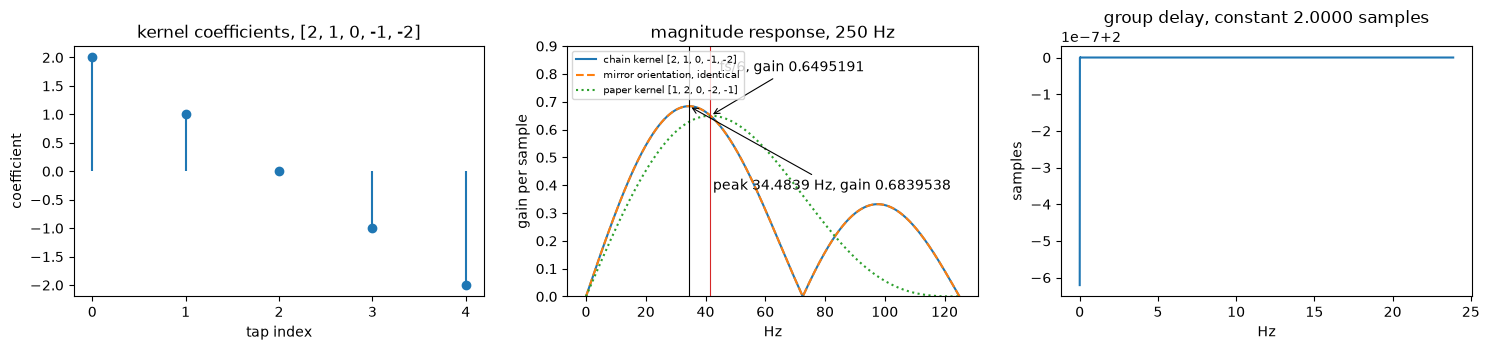

In [2]:
FS = 250.0
KERNEL = np.array([2.0, 1.0, 0.0, -1.0, -2.0])
KERNEL_PAPER = np.array([1.0, 2.0, 0.0, -2.0, -1.0])
TAPS = np.arange(5)

def magnitude(h, f, fs):
    '''Magnitude response of a finite kernel at the frequencies f, from its coefficients.'''
    f = np.atleast_1d(np.asarray(f, dtype=float))
    w = 2.0 * math.pi * f / fs
    return np.abs((h[None, :] * np.exp(-1j * w[:, None] * TAPS[None, :])).sum(axis=1))

def peak_of(h, fs):
    '''The band peak of the magnitude response on a dense grid, refined by a ternary search.'''
    grid = np.arange(0.0, fs / 2.0, 0.001)
    values = magnitude(h, grid, fs)
    lo = float(grid[int(np.argmax(values))] - 0.002)
    hi = lo + 0.004
    for _ in range(90):
        a = lo + (hi - lo) / 3.0
        b = hi - (hi - lo) / 3.0
        if float(magnitude(h, a, fs)[0]) < float(magnitude(h, b, fs)[0]):
            lo = a
        else:
            hi = b
    peak = 0.5 * (lo + hi)
    return peak, float(magnitude(h, peak, fs)[0])

h8 = KERNEL / 8.0
h8_paper = KERNEL_PAPER / 8.0
h8_mirror = -KERNEL[::-1] / 8.0
peak_250, gain_peak = peak_of(h8, 250.0)
peak_200, _ = peak_of(h8, 200.0)
gain_dc = float(magnitude(h8, 0.0, FS)[0])
gain_fs6 = float(magnitude(h8, FS / 6.0, FS)[0])
peak_paper, gain_paper = peak_of(h8_paper, 250.0)
band = np.arange(0.0, FS / 2.0, 0.25)
mirror_gap = float(np.max(np.abs(magnitude(h8, band, FS) - magnitude(h8_mirror, band, FS))))
w = np.linspace(1e-7, 0.6, 6001)
phase = np.unwrap(np.angle((KERNEL[None, :] * np.exp(-1j * w[:, None] * TAPS[None, :])).sum(axis=1)))
group = -np.gradient(phase, w)

print("kernel used by the chain                 :", KERNEL.astype(int).tolist(), "divided by eight")
print("impulse response of the stage            :", KERNEL.astype(int).tolist())
print("magnitude peak at 250 Hz                 : %.4f Hz" % peak_250)
print("magnitude peak at 200 Hz                 : %.4f Hz" % peak_200)
print("peak gain of the kernel                  : %.7f" % gain_peak)
print("gain at DC, exact zero                   : %.1e" % gain_dc)
print("gain at fs/6, that is %.4f Hz          : %.7f" % (FS / 6.0, gain_fs6))
print("group delay of the kernel over the band  : %.4f samples" % float(np.mean(group)))
print("mirror orientation [%s] against the chain kernel" % ", ".join(str(int(v)) for v in -KERNEL[::-1]))
print("  largest magnitude difference over the band : %.2e" % mirror_gap)
print("paper kernel [%s] peaks at                : %.4f Hz with gain %.7f"
      % (", ".join(str(int(v)) for v in KERNEL_PAPER), peak_paper, gain_paper))

BUDGET = (("low-pass, equation 3", 5.0), ("high-pass, equation 6", 14.86),
          ("five point derivative, equation 9", 2.0), ("window integration, equation 11", 18.25))
print()
print("pipeline group delay, per stage and in total, at 250 Hz")
for label, value in BUDGET:
    print("  %-34s %6.2f samples  %6.1f ms" % (label, value, value * 4.0))
total = float(sum(value for _label, value in BUDGET))
print("  %-34s %6.2f samples  %6.1f ms" % ("total", total, total * 4.0))

fig, axes = plt.subplots(1, 3, figsize=(15.0, 3.6))
axes[0].stem(TAPS, KERNEL, basefmt=" ")
axes[0].set_title("kernel coefficients, [2, 1, 0, -1, -2]")
axes[0].set_xlabel("tap index")
axes[0].set_ylabel("coefficient")
axes[0].set_xticks(list(TAPS))
freq = np.linspace(0.0, FS / 2.0, 1500)
axes[1].plot(freq, magnitude(h8, freq, FS), label="chain kernel [2, 1, 0, -1, -2]")
axes[1].plot(freq, magnitude(h8_mirror, freq, FS), linestyle="--",
             label="mirror orientation, identical")
axes[1].plot(freq, magnitude(h8_paper, freq, FS), linestyle=":",
             label="paper kernel [1, 2, 0, -2, -1]")
axes[1].axvline(peak_250, color="black", linewidth=0.8)
axes[1].axvline(FS / 6.0, color="tab:red", linewidth=0.8)
axes[1].annotate("peak %.4f Hz, gain %.7f" % (peak_250, gain_peak), xy=(peak_250, gain_peak),
                 xytext=(peak_250 + 8.0, gain_peak - 0.30),
                 arrowprops=dict(arrowstyle="->", linewidth=0.8))
axes[1].annotate("fs/6, gain %.7f" % gain_fs6, xy=(FS / 6.0, gain_fs6),
                 xytext=(FS / 6.0 + 3.0, gain_fs6 + 0.16),
                 arrowprops=dict(arrowstyle="->", linewidth=0.8))
axes[1].set_title("magnitude response, 250 Hz")
axes[1].set_xlabel("Hz")
axes[1].set_ylabel("gain per sample")
axes[1].set_ylim(0.0, 0.9)
axes[1].legend(loc="upper left", fontsize=7)
axes[2].plot(w * FS / (2.0 * math.pi), group)
axes[2].set_title("group delay, constant %.4f samples" % float(np.mean(group)))
axes[2].set_xlabel("Hz")
axes[2].set_ylabel("samples")
fig.tight_layout()
plt.show()

## 2. The chain, driven here, against the frozen fixture

The chain is one state object and one streaming entry point. Bulk is not a second mode: it is
streaming driven to completion, so the notebook drives the frozen acquisition adapter through the
frozen chain with one large chunk and compares every array the chain returns with the fixture.

The measured range and bit width of every stage are printed from the chain itself, because the
hardware budget depends on them.

acquisition path      : DatasetBulk over afdb/04015, channel 0, 250 Hz
samples driven        : 450000 in 10.7 s of wall clock
beats qrs             : 2596
RR intervals rr       : 2595 longest 51064 ms
envelope peaks        : 4777
arrays compared with the frozen fixture : 21
arrays differing       : none, every shared array is identical

measured range and bit width of every stage of this run
  masukan16     range         -29776 to          32752   signed 16 bit   unsigned not applicable
  lp            range       -1061200 to        1179072   signed 22 bit   unsigned not applicable
  hp            range      -16974032 to       19286208   signed 26 bit   unsigned not applicable
  turunan       range       -4792318 to        3831762   signed 24 bit   unsigned not applicable
  kuadrat       range              0 to      350438400   signed 30 bit   unsigned 29
  jendela       range              0 to     3105281786   signed 33 bit   unsigned 32
  ambang        range              0 to      20

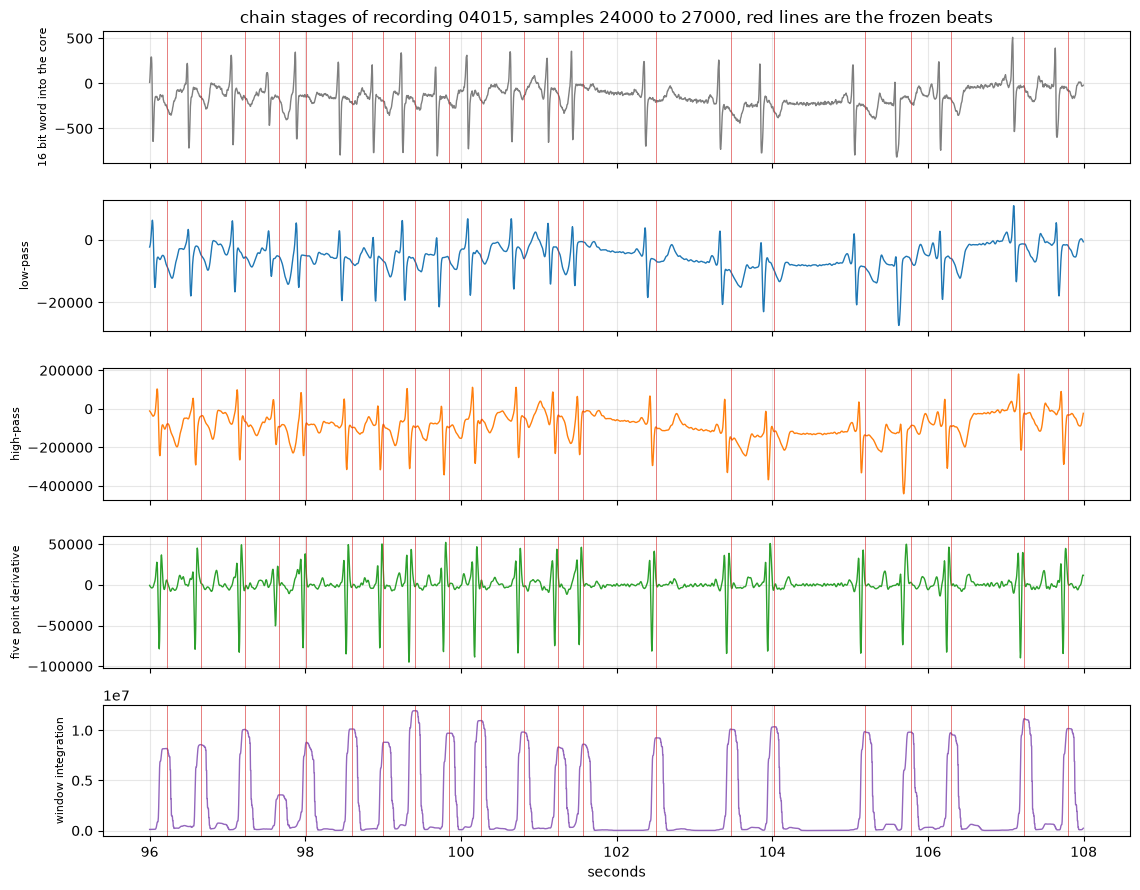

In [3]:
sys.path.insert(0, str(RANTAI))
import adapter as A
import rantai as R

fixture = np.load(FIXTURE)
chain = R.Rantai(semai_aktif=True, aturan_t=True, besaran="turunan")
source = A.DatasetBulk(str(DATA / "afdb" / "04015"), 450_000, 0)
source.open()
started = time.time()
samples, driven = source.drive(chain, 65536)
wall = time.time() - started
result = chain.hasil()
shared = [key for key in sorted(fixture.files) if key in result]
differing = []
for key in shared:
    if np.asarray(result[key]).shape != fixture[key].shape:
        differing.append("%s (shape)" % key)
    elif int(np.count_nonzero(np.asarray(result[key]) != np.asarray(fixture[key]))) != 0:
        differing.append(key)

print("acquisition path      : DatasetBulk over afdb/04015, channel 0, 250 Hz")
print("samples driven        :", samples, "in %.1f s of wall clock" % wall)
print("beats qrs             :", int(result["qrs"].size))
print("RR intervals rr       :", int(result["rr"].size), "longest", int(result["rr"].max()), "ms")
print("envelope peaks        :", int(result["puncak"].size))
print("arrays compared with the frozen fixture :", len(shared))
print("arrays differing       :", differing if differing else "none, every shared array is identical")
print()
print("measured range and bit width of every stage of this run")
ranges = chain.rentang_terukur()
widths = chain.lebar()
unsigned = chain.lebar_tanpa_tanda()
for key in ("masukan16", "lp", "hp", "turunan", "kuadrat", "jendela", "ambang", "search_back",
            "rr", "gelombang_t"):
    lo, hi = ranges[key]
    print("  %-13s range %14d to %14d   signed %2d bit   unsigned %s"
          % (key, lo, hi, widths[key], unsigned[key] if unsigned[key] else "not applicable"))
print()
print("step S7 rhythm check counters, raw kept split dropped gap :",
      list(int(v) for v in result["rr_rhythm_state"]))

resource = {
    "masukan16": ("16 bit word into the core", "tab:gray"),
    "lp": ("low-pass, equation 3", "tab:blue"),
    "hp": ("high-pass, equation 6", "tab:orange"),
    "turunan": ("five point derivative, equation 9", "tab:green"),
    "jendela": ("window integration, equation 11", "tab:purple"),
}
a, b = 24000, 27000
t = np.arange(a, b) / FS
fig, axes = plt.subplots(len(resource), 1, figsize=(11.5, 9.0), sharex=True)
for ax, (key, (label, colour)) in zip(axes, resource.items()):
    ax.plot(t, np.asarray(fixture[key][a:b], dtype=float) / (1 << R.GESER_KIRI), color=colour,
            linewidth=1.0)
    ax.set_ylabel(label.split(",")[0], fontsize=8)
    ax.grid(alpha=0.3)
    for beat in fixture["qrs"]:
        if a <= beat < b:
            ax.axvline(beat / FS, color="tab:red", linewidth=0.7, alpha=0.6)
axes[0].set_title("chain stages of recording 04015, samples %d to %d, red lines are the frozen beats"
                  % (a, b))
axes[-1].set_xlabel("seconds")
fig.tight_layout()
plt.show()

## 3. Validation level 1: one closed form theorem per stage

Level 1 asks whether each stage satisfies its own closed form property, on the data that really
flows through the chain and not only on an artificial series. Eight of the nine gate items pass.
The one failure is T3, the five point derivative, and its cause is the kernel orientation of
section 1: the gate measures the peak of the chain kernel at 34.4840 Hz while the locked value on
the paper kernel is fs/6. Aviv ruled on 20 October 2026 that the orientation the chain already
used is kept, so T3 stands as a recorded baseline condition of step S3 and not as a regression.

uji_00_teorema.py sha256 2fa0783586bbbbd544381ff56c3e4bb2 | ran now in 16.9 s, exit code 1

AFIB-LITE phase 6 step S3 gate: one closed form theorem per chain stage
fixture     : /home/avivsabilalm/hackathon-semiconductor-programs/nabdha-afib-lite/model/rantai-afib-lite/fixture/04015_30m.npz, 22032128 bytes
fixture sha : 91ff408fb1b7880a124d28bcc4205038935d4a3a2dbabb4c0f7d161d89e8ac4d matches the frozen fingerprint
notebook ref: acuan_fase imported, used as the notebook route of the comparisons
input       : recording 04015, 250 Hz, channel 0, 450000 samples, clamped samples not counted here
chain run   : 6.7 s streaming over 450000 samples
chain against the fixture: 21 arrays compared, all identical
real states captured: 4777 threshold calls, 2586 RR calls, 4777 slope measurements
per theorem result, one line each
------------------------------------------------------------------------------------------------------------------------------------
T1 low-pass        : impulse response [1,

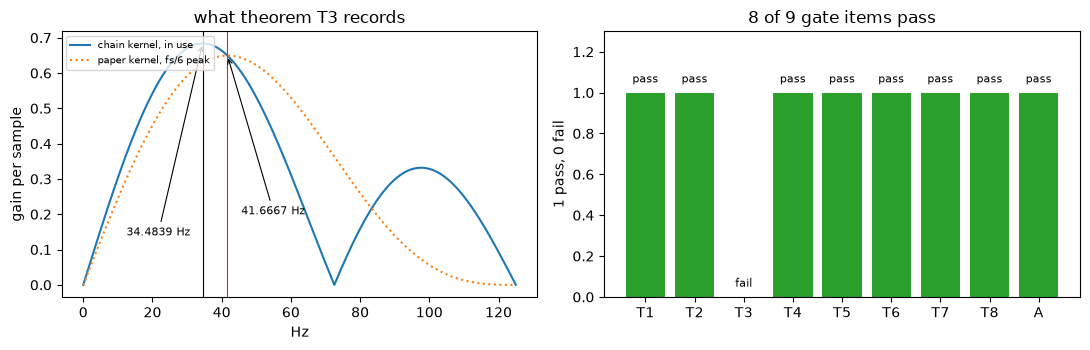

In [4]:
text, digest, how = gate_run("uji_00_teorema")
print("uji_00_teorema.py sha256", digest[:32], "|", how)
print()
show(text)
print()
passed = len(re.findall(r"^[TA][0-9 ].*LULUS$", text, flags=re.MULTILINE))
failed_lines = re.findall(r"^([TA][0-9][^\n]*?)\s*:\s.*GAGAL$", text, flags=re.MULTILINE)
failed = len(re.findall(r"GAGAL$", text, flags=re.MULTILINE))
summary = one_line(text, r"^gate items: .*$").group(0)
verdict = one_line(text, r"^gate S3: .*$").group(0)
print("theorems that pass                  :", passed)
print("theorems that fail                  :", failed, failed_lines)
print("gate summary line                   :", summary)
print("gate verdict line                   :", verdict)
t3 = one_line(text, r"^T3 five point der.*$").group(0)
t3_chain = one_line(t3, r"the chain kernel \[[^\]]*\] peaks at [\d.]+ Hz").group(0).strip()
t3_paper = one_line(t3, r"the paper kernel \[[^\]]*\] peaks at [\d.]+ Hz").group(0).strip()
t3_stage = one_line(t3, r"the stage itself measured on a sinusoid grid[^\|]*").group(0).strip()
t3_delay = one_line(t3, r"group delay: the kernel is antisymmetric[^\|]*").group(0).strip()
print("the T3 line reports the two kernels:")
print("  " + t3_chain)
print("  " + t3_paper)
print("  " + t3_stage)
print("  " + t3_delay)
print()
print("the peak measured by the gate on its own grid is %.4f Hz, the same item on the finer search"
      " of section 1 is %.4f Hz, and the locked value on the paper kernel is %.4f Hz, which is fs/6"
      % (float(re.search(r"peaks at ([\d.]+) Hz", t3_chain).group(1)), peak_250, FS / 6.0))

fig, axes = plt.subplots(1, 2, figsize=(11.0, 3.6))
axes[0].plot(freq, magnitude(h8, freq, FS), label="chain kernel, in use")
axes[0].plot(freq, magnitude(h8_paper, freq, FS), linestyle=":", label="paper kernel, fs/6 peak")
axes[0].axvline(peak_250, color="black", linewidth=0.8)
axes[0].axvline(FS / 6.0, color="tab:red", linewidth=0.8)
axes[0].annotate("%.4f Hz" % peak_250, xy=(peak_250, gain_peak), xytext=(peak_250 - 22.0, 0.14),
                 arrowprops=dict(arrowstyle="->", linewidth=0.8), fontsize=8)
axes[0].annotate("%.4f Hz" % (FS / 6.0), xy=(FS / 6.0, gain_paper),
                 xytext=(FS / 6.0 + 4.0, 0.20), arrowprops=dict(arrowstyle="->", linewidth=0.8),
                 fontsize=8)
axes[0].set_title("what theorem T3 records")
axes[0].set_xlabel("Hz")
axes[0].set_ylabel("gain per sample")
axes[0].legend(fontsize=7, loc="upper left")
labels = ["T1", "T2", "T3", "T4", "T5", "T6", "T7", "T8", "A"]
states = []
for label in labels:
    hit = [line for line in text.splitlines()
           if line.startswith(label) and len(line) > len(label) and line[len(label)] == " "]
    states.append(1 if hit and hit[0].rstrip().endswith("LULUS") else 0)
axes[1].bar(labels, states, color=["tab:green" if state else "tab:red" for state in states])
axes[1].set_ylim(0, 1.3)
axes[1].set_title("%d of %d gate items pass" % (passed, passed + failed))
axes[1].set_ylabel("1 pass, 0 fail")
for index, state in enumerate(states):
    axes[1].text(index, state + 0.05, "pass" if state else "fail", ha="center", fontsize=8)
fig.tight_layout()
plt.show()

## 4. Validation level 2: four adapters over one core

Four adapters carry one interface, `DatasetBulk`, `DatasetStream`, `AttysBulk` and `AttysStream`.
The core never sees a sample rate, a bit width or the origin of the data.

`uji_02_adapter.py` proves the adapter contract itself against the frozen fixture: the word series of
the dataset path differs from the fixture input in zero of 450000 words, the same source gives the
same index, value and marker through the bulk path and the stream path, and the clamp marker
lights on the recorded 402 samples.

`uji_03_ekivalensi.py` then proves equality across the four modes, including the chunk sizes 1, 7, 64,
4096 and 450000, which is the evidence that bulk is streaming driven to completion and not a
second mode.

uji_02_adapter.py sha256 9802947df8fbb1fed4583e606a993be3 | ran now in 91.3 s, exit code 0

S2 gate, four adapters over one interface, against the frozen fixture
fixture    : /home/avivsabilalm/hackathon-semiconductor-programs/nabdha-afib-lite/model/rantai-afib-lite/fixture/04015_30m.npz
recording  : /home/avivsabilalm/.hermes/cache/scratch/afib/afdb_local/04015
interpreter: /home/avivsabilalm/.venvs/jupyter/bin/python
stage 0, the frozen fixture is not touched
[ 1] PASS  fixture sha256 is the frozen hash                          91ff408fb1b7880a ...
[ 2] PASS  fixture masukan16 carries 450000 words                     shape (450000,) dtype int64
[ 3] PASS  fixture masukan16 tops out at the locked clamp word        max |word| 32752, clamp word 32752
[ 4] PASS  every fixture word is the locked count times sixteen       remainders present [0]
[ 5] PASS  no adapter marker array in the fixture                     33 arrays, the only penanda is the chain RR gate of 2579 entries
stage 1, the

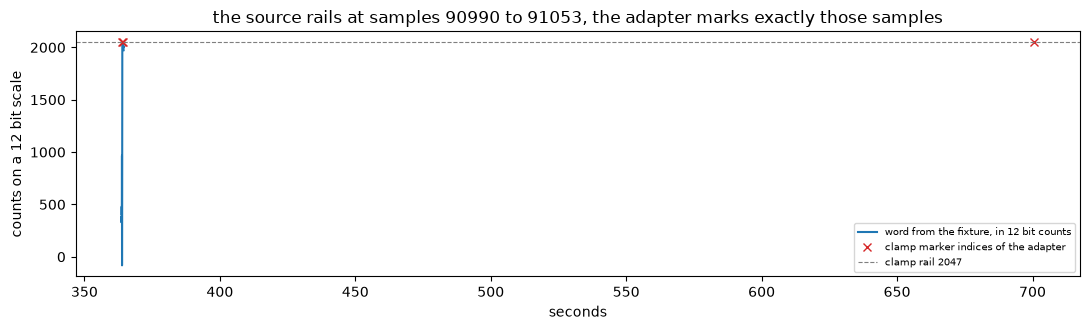

In [5]:
text, digest, how = gate_run("uji_02_adapter")
print("uji_02_adapter.py sha256", digest[:32], "|", how)
print()
show(text)
print()
checks = one_line(text, r"^\d+ checks, .*$").group(0)
verdict = one_line(text, r"^gate S2: .*$").group(0)
word_line = one_line(text, r"value16 equals fixture masukan16 elementwise.*$").group(0)
clamp_line = one_line(text, r"^\[10\].*$").group(0)
marker_line = one_line(text, r"the clamp marker lights on exactly those indices.*$").group(0)
stream_line = one_line(text, r"DatasetStream value16 series equals DatasetBulk.*$").group(0)
bulk_stream_core = one_line(text, r"every core array is identical between bulk and stream.*$").group(0)
chunk_line = one_line(text, r"the chunk size does not change the result.*$").group(0) \
    if "the chunk size does not change the result" in text else ""
print("checks                              :", checks)
print("gate verdict                        :", verdict)
print("word series against the fixture     :", word_line.split("  ")[-1])
print("clipped samples on the source       :", clamp_line.split("  ")[-1])
print("clamp marker indices                :", marker_line.split("  ")[-1])
print("stream against bulk, value16        :", stream_line.split("  ")[-1])
print("core over the two dataset paths     :", bulk_stream_core.split("  ")[-1])
if chunk_line:
    print("chunk sizes                         :", chunk_line.split("  ")[-1])

guard = int(result["masukan16"].size)
bad_words = int(np.count_nonzero(np.asarray(result["masukan16"]) != np.asarray(fixture["masukan16"])))
rail = int(R.CLAMP) << int(R.GESER_KIRI)
clamped = int(np.count_nonzero(np.abs(np.asarray(fixture["masukan16"])) >= rail))
print()
print("here, on this run, of %d words the chain received, differing from the fixture input: %d"
      % (guard, bad_words))
print("the fixture word tops out at %d, which is the locked clamp %d shifted left %d"
      % (int(np.abs(np.asarray(fixture["masukan16"])).max()), int(R.CLAMP), int(R.GESER_KIRI)))
print("samples sitting on the clamp rail   :", clamped,
      "and the adapter marker counts 402 clipped samples, because four samples landed exactly on"
      " 2047 and are not clipped")

window = np.arange(90900, 91120)
fig, ax = plt.subplots(figsize=(11.0, 3.4))
ax.plot(window / FS, np.asarray(fixture["masukan16"][90900:91120], dtype=float) / (1 << R.GESER_KIRI),
        color="tab:blue", label="word from the fixture, in 12 bit counts")
ax.plot(np.array([90990, 91053, 175169]) / FS,
        np.zeros(3) + rail / (1 << R.GESER_KIRI),
        "x", color="tab:red", label="clamp marker indices of the adapter")
ax.axhline(rail / (1 << R.GESER_KIRI), color="tab:gray", linestyle="--", linewidth=0.8,
           label="clamp rail %d" % (rail >> R.GESER_KIRI))
ax.set_title("the source rails at samples 90990 to 91053, the adapter marks exactly those samples")
ax.set_xlabel("seconds")
ax.set_ylabel("counts on a 12 bit scale")
ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

In [6]:
text, digest, how = gate_run("uji_03_ekivalensi")
print("uji_03_ekivalensi.py sha256", digest[:32], "|", how)
print()
show(text)
print()
checks = one_line(text, r"^\d+ checks, .*$").group(0)
verdict = one_line(text, r"^gate S4: .*$").group(0)
combined = re.search(r"combined fingerprint, all paths on \S+\s+([0-9a-f]{32,64})", text)
print("checks                       :", checks)
print("gate verdict                 :", verdict)
print("the combined fingerprint of every path on 04015 :", combined.group(1)[:32])
print("the mode fingerprints of this gate            : dataset_bulk and dataset_stream share one"
      " digest, attys_bulk, attys_stream250 and attys_stream500 share another")
print("the four modes of this gate  : DatasetBulk, DatasetStream, AttysBulk, AttysStream")
print("the result of the gate       : the same recording gives the same beat list and the same"
      " window decisions in every mode, bit for bit")

uji_03_ekivalensi.py sha256 681ba8aa6b0e187d93c6da3e78262947 | ran now in 291.3 s, exit code 0

S4 gate, validation level 2, equality across the four adapter modes
recording  : /home/avivsabilalm/.hermes/cache/scratch/afib/afdb_local/04015
fixture    : /home/avivsabilalm/hackathon-semiconductor-programs/nabdha-afib-lite/model/rantai-afib-lite/fixture/04015_30m.npz
sessions   : /home/avivsabilalm/hackathon-semiconductor-programs/nabdha-afib-lite/model/rantai-afib-lite/fixture/attys
interpreter: /home/avivsabilalm/.venvs/jupyter/bin/python
stage 0, the frozen inputs, read and never written
[ 1] PASS  the frozen fixture still carries its frozen sha256         91ff408fb1b7880a124d28bcc4205038 ...
[ 2] PASS  the synthetic sessions match the sha256 of their own meta  250 Hz: 450000 frames, sha256 matches; 125 Hz: 225000 frames, sha256 matches; 500 Hz: 900000 frames, sha256 matches
     INFO  live Attys Bluetooth path                                  NOT TESTED, pyattyscomm and a device are a

## 5. Validation level 3: reference validation and the extra test set

Level 3 is window classification against rhythm annotation, which is sensitivity, specificity and
accuracy over 30 minute windows. The thresholds are not touched: the frozen pair of the chain,
ratio above 0.21 and entropy above 0.70, is used exactly as it is, and both test records are pure
hold-out because every threshold was derived on 04015 before they were read.

One record is deliberately not a 250 Hz record: NSRDB runs at 128 Hz and MITDB at 360 Hz, so both
exercise the rate path. MITDB carries beat annotation and not rhythm annotation, so its window
classification is not measurable and only its beat agreement is reported.

uji_06_referensi.py sha256 fe0ac649747203ae249fe91e6acc87af | ran now in 49.5 s, exit code 0

S6 gate, validation level 3 and the additional test set, records outside 04015
data root   : /home/avivsabilalm/nabdha-data
interpreter : /home/avivsabilalm/.venvs/jupyter/bin/python
window      : 1800 s per record, 450000 samples at the locked 250 Hz
records     : afdb/04043, afdb/04126, nsrdb/16265, mitdb/100
binding note: every number below stands on the five point derivative kernel the chain uses today,
              [2, 1, 0, -1, -2] divided by eight. If that kernel changes, every number of this step has to be recomputed.
stage 0, hold-out discipline and the frozen conventions, read and never written
[ 1] PASS  this file derives no threshold on any record                   no call of the threshold derivation function appears in this file and no threshold grid is swept over a test record, so every number below is a hold-out measurement
[ 2] PASS  the threshold pair of the gate is the froze

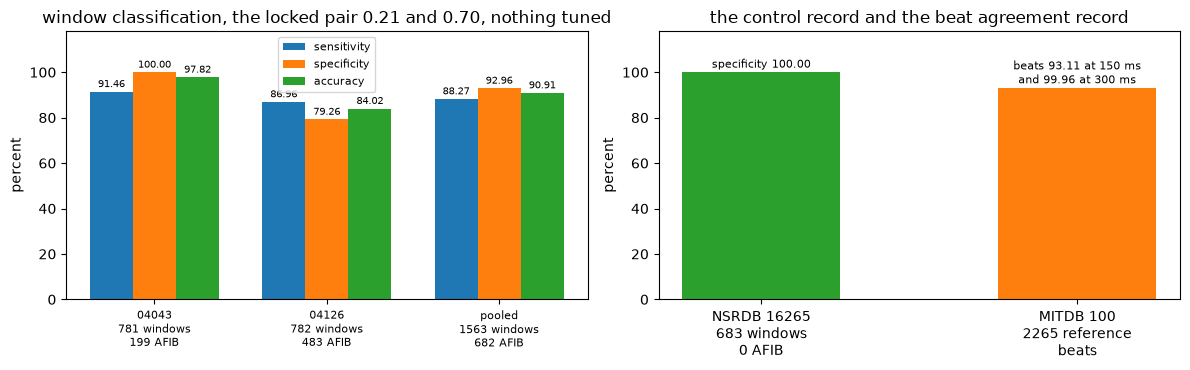

In [7]:
text, digest, how = gate_run("uji_06_referensi")
print("uji_06_referensi.py sha256", digest[:32], "|", how)
print()
show(text)
print()
records = {}
for name in ("04043", "04126", "16265", "100"):
    row = re.search(r"^\s+(?:afdb|nsrdb|mitdb)/%s\s+\S+\s+\S+\s+\S+\s+\S+\s+\S+\s+\S+\s+\S+"
                    r"\s+\S+\s+\S+\s+\S+\s+\S+\s+\S+\s*$" % name, text, flags=re.MULTILINE)
    if row is None:
        raise ValueError("the record table row of %s was not found" % name)
    records[name] = row.group(0).split()
combined = re.search(r"^     combined AFDB test records, (\d+) windows, (\d+) AFIB, (\d+) N\s*$",
                     text, flags=re.MULTILINE)
scores = re.search(r"^     sensitivity ([\d.]+) percent, specificity ([\d.]+) percent, accuracy"
                   r" ([\d.]+) percent, gate firing rate ([\d.]+) percent\s*$", text,
                   flags=re.MULTILINE)
mitdb_line = one_line(text, r"^\[28\] PASS  beat agreement measured on mitdb/100.*$").group(0)
mitdb_150 = re.search(r"tolerance 150 ms: beats (\d+) of (\d+) reference matched \(([\d.]+) "
                      r"percent\)", mitdb_line)
mitdb_300 = re.search(r"tolerance 300 ms: beats (\d+) of (\d+) reference matched \(([\d.]+) "
                      r"percent\)", mitdb_line)
delay = re.search(r"group delay of ([\d.]+) samples or ([\d.]+) ms at 250 Hz", text)
checks = one_line(text, r"^\d+ checks, .*$").group(0)
verdict = one_line(text, r"^gate S6: .*$").group(0)

print("one line per record, from the table of the gate")
print("  record     rate  lead    beats windows  AFIB    sens    spec     acc")
for name in ("04043", "04126", "16265", "100"):
    row = records[name]
    print("  %-10s %s  %-5s %5s %7s %5s %7s %7s %7s"
          % (row[0], row[1], row[2], row[4], row[5], row[6], row[7], row[8], row[9]))
print()
print("checks                            :", checks)
print("gate verdict                      :", verdict)
if combined:
    print("combined AFDB test records        :", combined.group(1), "windows including",
          combined.group(2), "AFIB and", combined.group(3), "N")
if scores:
    print("combined sensitivity              :", scores.group(1), "percent")
    print("combined specificity              :", scores.group(2), "percent")
    print("combined accuracy                 :", scores.group(3), "percent")
print("NSRDB 16265, the non fibrillation control, has 0 AFIB windows out of 683, so its"
      " specificity is 100.00 percent and the count of windows is what makes the control"
      " non vacuous")
print("MITDB 100, window classification not measurable, beat agreement at 150 ms :",
      mitdb_150.group(3), "percent of", mitdb_150.group(2), "reference beats")
print("MITDB 100, beat agreement at 300 ms                                      :",
      mitdb_300.group(3), "percent of", mitdb_300.group(2), "reference beats")
print("pipeline group delay reported next to the beat agreement                 :",
      delay.group(1), "samples or", delay.group(2), "ms at 250 Hz")

labels = ["04043\n781 windows\n199 AFIB", "04126\n782 windows\n483 AFIB",
          "pooled\n1563 windows\n682 AFIB"]
sens = [float(records["04043"][7]), float(records["04126"][7]), float(scores.group(1))]
spec = [float(records["04043"][8]), float(records["04126"][8]), float(scores.group(2))]
acc = [float(records["04043"][9]), float(records["04126"][9]), float(scores.group(3))]
x = np.arange(3.0)
fig, axes = plt.subplots(1, 2, figsize=(12.0, 3.8))
axes[0].bar(x - 0.25, sens, 0.25, label="sensitivity")
axes[0].bar(x, spec, 0.25, label="specificity")
axes[0].bar(x + 0.25, acc, 0.25, label="accuracy")
axes[0].set_xticks(list(x))
axes[0].set_xticklabels(labels, fontsize=8)
axes[0].set_ylim(0, 118)
axes[0].set_title("window classification, the locked pair 0.21 and 0.70, nothing tuned")
axes[0].set_ylabel("percent")
axes[0].legend(fontsize=8)
for shift, values in ((-0.25, sens), (0.0, spec), (0.25, acc)):
    for index, value in enumerate(values):
        axes[0].text(index + shift, value + 2.0, "%.2f" % value, ha="center", fontsize=7)
axes[1].bar(["NSRDB 16265\n683 windows\n0 AFIB", "MITDB 100\n2265 reference\nbeats"],
            [100.0, float(mitdb_150.group(3))], color=["tab:green", "tab:orange"], width=0.5)
axes[1].set_ylim(0, 118)
axes[1].set_title("the control record and the beat agreement record")
axes[1].set_ylabel("percent")
axes[1].text(0, 102.0, "specificity 100.00", ha="center", fontsize=8)
axes[1].text(1, float(mitdb_150.group(3)) + 2.0,
             "beats 93.11 at 150 ms\nand 99.96 at 300 ms", ha="center", fontsize=8)
fig.tight_layout()
plt.show()

## 6. The locked operating point on the hold out windows

The triage gate is an AND of two features, the ratio RMSSD divided by the mean RR and the
normalized entropy of the window. Aviv locked operating point P1, ratio threshold 0.165 and
entropy threshold 0.63, on 20 October 2026. P1 was chosen on 04015 alone. The two test records,
04043 and 04126, are the hold-out set, and this section prints both the locked point and the two
backup points that were kept next to it.

The prevalence of the pool is printed with the numbers, because PPV and NPV are only readable next
to it.

uji_05_kebijakan_ambang.py sha256 c65a4dc723b8f8866416cb7570db4d75 | ran now in 38.7 s, exit code 0

S5c gate, operating point study of the triage policy, candidates from 04015 only
interpreter   : /home/avivsabilalm/.venvs/jupyter/bin/python
data root     : /home/avivsabilalm/nabdha-data
derivation    : 04015 alone, every point of P1 to P4
hold-out      : 04043 and 04126, used to measure only, never to choose
ratio arm     : the four derived points keep ratio at or above 0.050, so the gate stays a two feature AND gate
metric policy : sensitivity, specificity, accuracy, firing rate, PPV, NPV and miss rate, each with the prevalence of its set
stage 1, the frozen fixture, read and never written
     fixture sha256 measured                91ff408fb1b7880a124d28bcc4205038935d4a3a2dbabb4c0f7d161d89e8ac4d
     fixture sha256 locked                  91ff408fb1b7880a124d28bcc4205038935d4a3a2dbabb4c0f7d161d89e8ac4d
stage 2, the derivative kernel every number stands on, measured
     impulse res

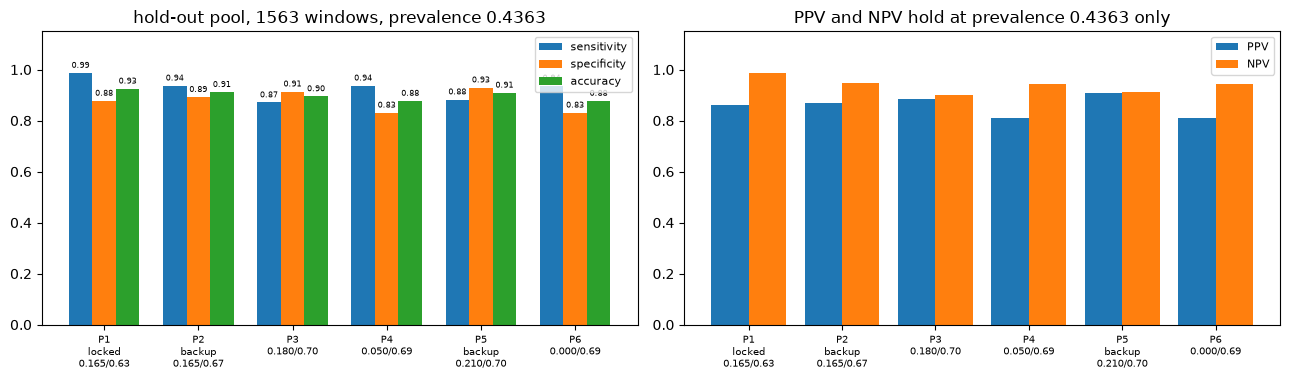

In [8]:
text, digest, how = gate_run("uji_05_kebijakan_ambang")
print("uji_05_kebijakan_ambang.py sha256", digest[:32], "|", how)
print()
show(trim_interval_sweep(text))
print()
checks = one_line(text, r"^summary: .*$").group(0)
verdict = one_line(text, r"^gate S5c: .*$").group(0)
pooled = re.search(r"^stage 5, the six points on pooled, (\d+) windows, (\d+) AFIB, prevalence"
                   r" ([\d.]+)\s*$", text, flags=re.MULTILINE)
rows = {}
for match in re.finditer(r"^\s+(P\d)\s+([\d.]+)/([\d.]+)\s+1563\s+682\s+(\d+)\s+(\d+)\s+(\d+)"
                         r"\s+(\d+)\s+([\d.]+)\s+([\d.]+)\s+([\d.]+)\s+([\d.]+)\s+([\d.]+)\s+"
                         r"([\d.]+)\s+([\d.]+)\s+(\d+)\s*$", text, flags=re.MULTILINE):
    rows[match.group(1)] = dict(ratio=match.group(2), entropy=match.group(3),
                                tp=int(match.group(4)), fp=int(match.group(5)),
                                fn=int(match.group(6)), tn=int(match.group(7)),
                                se=float(match.group(8)), sp=float(match.group(9)),
                                acc=float(match.group(10)), fire=float(match.group(11)),
                                ppv=float(match.group(12)), npv=float(match.group(13)),
                                miss=float(match.group(14)), blocked=int(match.group(15)))
hard = re.search(r"^  P1\s+0\.165/0\.63\s+782\s+483\s+\d+\s+\d+\s+\d+\s+\d+\s+([\d.]+)"
                 r"\s+([\d.]+)\s+([\d.]+)", text, flags=re.MULTILINE)
bite = re.search(r"P1  ratio 0\.165, entropy 0\.63 : decided by the ratio arm on 04015 (\d+)"
                 r" windows, on 04043 (\d+) windows, on 04126 (\d+) windows", text)
pooled_block = text[text.index("pooled over the full grid"):]
bound = re.search(r"^\s+best accuracy\s+([\d.]+)", pooled_block, flags=re.MULTILINE)
headroom = re.search(r"accuracy, bound ([\d.]+), best hold-out point ([\d.]+), headroom ([\d.]+)",
                     text)
poor = re.search(r"04043  P1, pair 0\.165 and 0\.63, accuracy ([\d.]+) against the bound ([\d.]+),"
                 r" headroom ([\d.]+)", text)
print("checks                       :", checks)
print("gate verdict                 :", verdict)
print("hold-out pool                :", pooled.group(1), "windows including", pooled.group(2),
      "AFIB and", int(pooled.group(1)) - int(pooled.group(2)), "N, prevalence", pooled.group(3))
print()
print("the locked point and the two backup points, on the hold-out pool")
for point in ("P1", "P2", "P5"):
    row = rows[point]
    print("  %s ratio %s entropy %s : sensitivity %.4f, specificity %.4f, accuracy %.4f,"
          " PPV %.4f, NPV %.4f, miss rate %.4f, firing rate %.4f"
          % (point, row["ratio"], row["entropy"], row["se"], row["sp"], row["acc"], row["ppv"],
             row["npv"], row["miss"], row["fire"]))
print()
print("the same six points, printed for the record where they are hardest")
for point in ("P1", "P5"):
    row = rows[point]
    print("  pooled %s : %d of %d windows called AFIB, ratio arm decided %d of them"
          % (point, row["tp"] + row["fp"], int(pooled.group(1)), row["blocked"]))
print("  on 04126, prevalence 0.6176, the locked point P1 reaches sensitivity %s and specificity"
      " %s, so on the hardest record the false alarm load is the price of the sensitivity"
      % (hard.group(1), hard.group(2)))
print("  the ratio arm of P1 is the deciding arm on %s windows of 04015, %s of 04043 and %s of"
      " 04126, so the ratio feature really takes part in decisions"
      % (bite.group(1), bite.group(2), bite.group(3)))
print()
print("how much room a threshold chosen on these very windows would hide")
print("  best accuracy on the pool over the whole grid of 12028 pairs :", bound.group(1))
print("  best hold-out point P1 accuracy                              :", headroom.group(2))
print("  headroom                                                     :", headroom.group(3),
      "accuracy points")
spread = max(row["acc"] for row in rows.values()) - min(row["acc"] for row in rows.values())
print("  the largest accuracy difference between the six points       : %.4f points" % spread)
print("  so the distance from P1 to the optimistic bound is %s accuracy points and the largest"
      " difference between the six points is %.4f points. The spread between the points is now"
      " the larger of the two, so this measure no longer places their order inside the"
      " selection noise, and it is left standing as it is measured"
      % (headroom.group(3), spread))
print("  04043 is near separable: P1 accuracy", poor.group(1), "against the bound", poor.group(2),
      ", headroom", poor.group(3), "points")

labels = ["P1\nlocked\n0.165/0.63", "P2\nbackup\n0.165/0.67", "P3\n0.180/0.70",
          "P4\n0.050/0.69", "P5\nbackup\n0.210/0.70", "P6\n0.000/0.69"]
order = ["P1", "P2", "P3", "P4", "P5", "P6"]
x = np.arange(6.0)
fig, axes = plt.subplots(1, 2, figsize=(13.0, 3.9))
for shift, key, name in ((-0.25, "se", "sensitivity"), (0.0, "sp", "specificity"),
                         (0.25, "acc", "accuracy")):
    values = [rows[point][key] for point in order]
    axes[0].bar(x + shift, values, 0.25, label=name)
axes[0].set_xticks(list(x))
axes[0].set_xticklabels(labels, fontsize=7)
axes[0].set_ylim(0, 1.15)
axes[0].set_title("hold-out pool, 1563 windows, prevalence %s" % pooled.group(3))
axes[0].legend(fontsize=8)
for shift, key in ((-0.25, "se"), (0.0, "sp"), (0.25, "acc")):
    for index, point in enumerate(order):
        axes[0].text(index + shift, rows[point][key] + 0.02, "%.2f" % rows[point][key],
                     ha="center", fontsize=6)
axes[1].bar(x - 0.2, [rows[point]["ppv"] for point in order], 0.4, label="PPV")
axes[1].bar(x + 0.2, [rows[point]["npv"] for point in order], 0.4, label="NPV")
axes[1].set_xticks(list(x))
axes[1].set_xticklabels(labels, fontsize=7)
axes[1].set_ylim(0, 1.15)
axes[1].set_title("PPV and NPV hold at prevalence %s only" % pooled.group(3))
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

## 7. Step S7: the 51 second pause, diagnosed

The locked chain reports one interval of 51064 ms on 04015, between the beats at sample 71399 and
sample 84165, that is 285.60 s to 336.66 s. The phase plan expected a threshold defect. The
diagnosis of step S7 says otherwise: the lead the chain consumes carries no beat activity in that
range at all, so the chain is consequent and not the cause.

The one change of step S7 is an integer rhythm check written beside the locked RR series, with
four marks: 0 keep, 1 split a missed beat into two exact halves, 2 drop a false detection, 3 mark a
recording gap. Nothing is added to or removed from the beat series `qrs`.

The lead claim is checked three ways in the last cell: the per second amplitude against half the
record median on both leads, the reference detector NeuroKit2 on the same window at the rate the
file declares and again at the rate that detector assumes by default, and the annotation file of
the record itself. Every reading is printed, including the one that does not support the simplest
reading of the claim.

In [9]:
text, digest, how = gate_run("uji_07_jeda_rr")
print("uji_07_jeda_rr.py sha256", digest[:32], "|", how)
print()
show(text)
print()
checks = one_line(text, r"^gate items: .*$").group(0)
verdict = one_line(text, r"^gate S7: .*$").group(0)
real = one_line(text, r"^LULUS  chain run .*04015.*$").group(0)
counters = re.search(r"the counters raw, kept, split, dropped, gap read \[([\d, ]+)\]", text)
longest = re.search(r"raw intervals (\d+), longest (\d+) ms between the beats at (\d+) and (\d+),"
                    r" its mark (\d+) \(exp \d+\), the longest interval not marked as a gap"
                    r" (\d+) ms", text)
print("checks                            :", checks)
print("gate verdict                      :", verdict)
print("raw intervals                     :", longest.group(1), "longest", longest.group(2),
      "ms between the beats at samples", longest.group(3), "and", longest.group(4))
print("the gap is inside                 : %.2f s to %.2f s"
      % (int(longest.group(3)) / FS, int(longest.group(4)) / FS))
print("mark of that interval             :", longest.group(5),
      "which means a recording gap, kept whole and kept out of the running average")
print("longest interval that is not a gap:", longest.group(6), "ms")
print("counters raw kept split dropped gap:", counters.group(1))
print()
with open(RANTAI / "fixture" / "rr_gap_before_04015.txt", encoding="utf-8") as handle:
    before = [line.split() for line in handle if line.strip() and not line.startswith("#")]
with open(RANTAI / "fixture" / "rr_gap_after_04015.txt", encoding="utf-8") as handle:
    after = [line.split() for line in handle if line.strip() and not line.startswith("#")]
raw_ms = np.array([int(row[1]) for row in before], dtype=np.int64)
raw_mark = np.array([int(row[2]) for row in before], dtype=np.int64)
cor_ms = np.array([int(row[1]) for row in after], dtype=np.int64)
cor_mark = np.array([int(row[2]) for row in after], dtype=np.int64)
print("the two frozen RR series of the fixture, column 1 an index, column 2 the interval in"
      " milliseconds, column 3 the mark")
print("  raw series        : %d intervals, total %d ms, mean %.1f ms, implied rate %.1f beats per"
      " minute" % (raw_ms.size, raw_ms.sum(), raw_ms.mean(), 60000.0 / raw_ms.mean()))
print("  corrected series  : %d entries, total %d ms, mean %.1f ms, implied rate %.1f beats per"
      " minute" % (cor_ms.size, cor_ms.sum(), cor_ms.mean(), 60000.0 / cor_ms.mean()))
print("  longest interval not marked as a gap: %d ms"
      % int(cor_ms[cor_mark != 3].max()))
print("  the rate implied by the corrected series, %.1f against %.1f beats per minute, is a"
      " hypothesis and not a measurement: the canonical missed beat rule presumes a regular"
      " rhythm, and this record is atrial fibrillation, so the rule over fires"
      % (60000.0 / cor_ms.mean(), 60000.0 / raw_ms.mean()))
print("  the raw series rr, the beats qrs and every frozen array are unchanged, so the fixture"
      " stays the oracle of the behaviour before the change and was not refrozen")

uji_07_jeda_rr.py sha256 60bb1b45b763ffb90f6c3af1602b85f8 | ran now in 10.0 s, exit code 0

S7 gate, the integer rhythm check over the RR series of the locked chain
fixture     : /home/avivsabilalm/hackathon-semiconductor-programs/nabdha-afib-lite/model/rantai-afib-lite/fixture/04015_30m.npz, 22032128 bytes
fixture sha : 91ff408fb1b7880a124d28bcc4205038935d4a3a2dbabb4c0f7d161d89e8ac4d matches the frozen fingerprint
rules       : above 83/50 of the running average is a missed beat, below 1/2 is a false detection, above the 3000 ms ceiling is a recording gap
markers     : keep 0, split 1, drop 2, gap 3
running avg : the integer median of the last 8 corrected intervals, from median_bulat
input       : recording /home/avivsabilalm/nabdha-data/afdb/04015, 450000 samples, channel 0, 250 Hz
A  a synthetic missed beat is split into two exact halves
------------------------------------------------------------------------------------------------------------------------------------
LULUS  raw 204

the two frozen RR series of the fixture, column 1 an index, column 2 the interval in milliseconds, column 3 the mark
  raw series        : 2595 intervals, total 1798936 ms, mean 693.2 ms, implied rate 86.6 beats per minute
  corrected series  : 2983 entries, total 1796632 ms, mean 602.3 ms, implied rate 99.6 beats per minute
  longest interval not marked as a gap: 1112 ms
  the rate implied by the corrected series, 99.6 against 86.6 beats per minute, is a hypothesis and not a measurement: the canonical missed beat rule presumes a regular rhythm, and this record is atrial fibrillation, so the rule over fires
  the raw series rr, the beats qrs and every frozen array are unchanged, so the fixture stays the oracle of the behaviour before the change and was not refrozen


wfdb.rdrecord without sampto raises ValueError: could not broadcast input array from shape (450000,) into shape (9205760,)
the header of the three AFDB records declares about ten hours while the .dat file carries thirty minutes, that is 450000 samples, so a reader must cut at 450000 samples or wfdb fails on the broadcast. The warning is repeated in the vault note of this step.
with sampto=450000 : (450000, 2) samples at 250 Hz, leads ['ECG1', 'ECG2']
  ECG1 : record median of the per second peak 1.730 mV, window 0.075 to 3.385 mV, seconds below half the median 43 of 52, against 43 of 52 if the count window is shifted one second later
  ECG2 : record median of the per second peak 2.330 mV, window 0.720 to 4.430 mV, seconds below half the median 2 of 52, against 3 of 52 if the count window is shifted one second later
  ECG1 falls below half its record median over 43 of the 52 seconds, ECG2 over 2, so the heart is beating and the lead the chain consumes is not carrying it. That is the sig

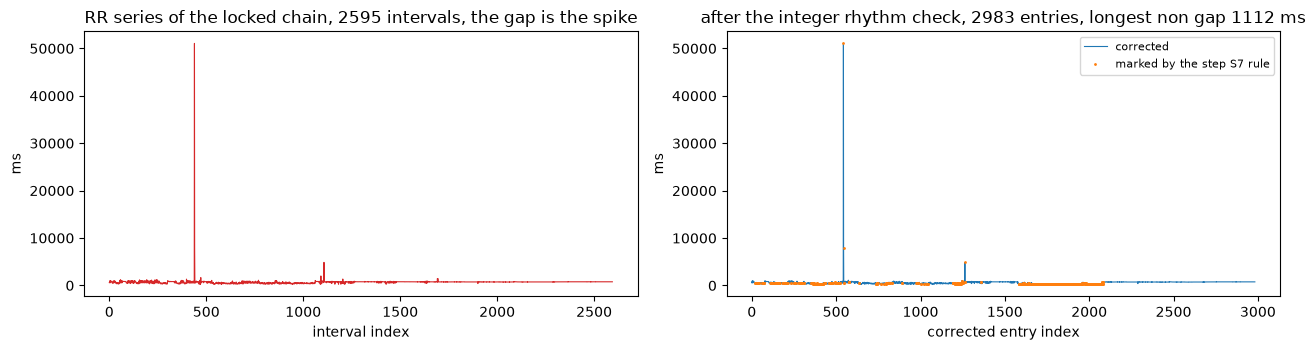

In [10]:
import wfdb

record = str(DATA / "afdb" / "04015")
try:
    whole = wfdb.rdrecord(record)
    print("no exception, shape", whole.p_signal.shape)
except ValueError as error:
    print("wfdb.rdrecord without sampto raises ValueError:", error)
print("the header of the three AFDB records declares about ten hours while the .dat file carries"
      " thirty minutes, that is 450000 samples, so a reader must cut at 450000 samples or wfdb"
      " fails on the broadcast. The warning is repeated in the vault note of this step.")
signal = wfdb.rdrecord(record, sampto=450_000)
print("with sampto=450000 :", signal.p_signal.shape, "samples at", signal.fs, "Hz, leads",
      signal.sig_name)

start, stop = int(longest.group(3)), int(longest.group(4))
seconds = int(signal.fs)
for channel, name in enumerate(signal.sig_name):
    per_second = np.abs(signal.p_signal[:, channel])
    per_second = per_second[: (per_second.size // seconds) * seconds]
    per_second = per_second.reshape(-1, seconds).max(axis=1)
    median = float(np.median(per_second))
    first_index = start // seconds
    last_index = stop // seconds
    window = per_second[first_index:last_index + 1]
    quiet = int(np.count_nonzero(window < 0.5 * median))
    shifted = int(np.count_nonzero(per_second[first_index + 1:last_index + 2] < 0.5 * median))
    print("  %s : record median of the per second peak %.3f mV, window %.3f to %.3f mV, seconds"
          " below half the median %d of %d, against %d of %d if the count window is shifted one"
          " second later" % (name, median, float(window.min()), float(window.max()), quiet,
                            window.size, shifted, window.size))
print("  ECG1 falls below half its record median over 43 of the 52 seconds, ECG2 over 2, so the"
      " heart is beating and the lead the chain consumes is not carrying it. That is the"
      " signature of a contact loss and it is why the chain reports a 51064 ms interval without"
      " being at fault. The count of ECG2 moves by one with the choice of window edge, and both"
      " readings are printed above rather than one being picked.")

print()
print("reference detector on the same window, NeuroKit2")
window = signal.p_signal[start:stop, 0]
try:
    import neurokit2 as nk
    _, info = nk.ecg_peaks(window, sampling_rate=seconds)
    declared = np.asarray(info["ECG_R_Peaks"], dtype=int)
    _, info_default = nk.ecg_peaks(window)
    assumed = np.asarray(info_default["ECG_R_Peaks"], dtype=int)
    whole_peaks = np.asarray(nk.ecg_findpeaks(signal.p_signal[:, 0], sampling_rate=seconds,
                                             method="neurokit")["ECG_R_Peaks"], dtype=int)
    spacing = float(np.diff(whole_peaks).mean()) / seconds * 1000.0
    gaps = np.diff(whole_peaks) / seconds
    widest = int(np.argmax(gaps))
    print("  NeuroKit2 at the rate this file declares, %d Hz : %d peaks inside the %.3f s window"
          % (seconds, declared.size, (stop - start) / seconds))
    print("  NeuroKit2 at its own default of 1000 Hz, which is four times the rate of this file :"
          " %d peak inside the same window" % assumed.size)
    print("  NeuroKit2 over the whole 450000 sample record at the declared rate : %d peaks, one"
          " every %.0f ms on average" % (whole_peaks.size, spacing))
    print("  widest interval inside that peak train over the whole record : %.3f s, between %.2f s"
          " and %.2f s" % (float(gaps[widest]), whole_peaks[widest] / seconds,
                           whole_peaks[widest + 1] / seconds))
    print("  this record gives one peak every %.0f ms on average, so the window is not silent for"
          " the reference detector either, but a window whose chain interval is one beat long is"
          " still a window the reference detector nearly abandons" % spacing)
    print("  the count of one beat appears only when the window is passed at the default rate of"
          " 1000 Hz, four times the rate of this file, and it is reported here as a rate mismatch"
          " and not as the reference reading. The contact loss rests on the amplitude evidence"
          " above, which does not depend on that count")
except Exception as problem:
    print("  NeuroKit2 did not run here:", problem)
try:
    marks = wfdb.rdann(record, "atr", sampto=450_000)
    symbols = sorted(set(str(s) for s in marks.symbol))
    print("  the annotation file of this record carries %d annotations over the first 450000"
          " samples, with symbols %s and not one of them a beat, so this record carries no beat"
          " reference of its own inside the window"
          % (int(np.asarray(marks.sample).size), symbols))
except Exception as problem:
    print("  the annotation file of this record did not read here:", problem)

print()
print("the second finding of step S7, the 4856 ms interval")
frozen = np.load(FIXTURE)
beats = np.asarray(frozen["qrs"]).ravel().astype(int)
intervals = np.diff(beats) / seconds * 1000.0
suspect = int(np.nonzero(np.isclose(intervals, 4856.0))[0][0])
left, right = int(beats[suspect]), int(beats[suspect + 1])
reference = np.asarray(frozen["puncak_acuan_neurokit"]).ravel().astype(int)
inside = reference[(reference > left) * (reference < right)]
between = int(np.count_nonzero((beats > left) * (beats < right)))
print("  the interval of 4856 ms runs from the beat at sample %d to the beat at sample %d, and the"
      " locked beat series carries %d beats between them" % (left, right, between))
print("  the reference peak array frozen in the fixture carries %d peaks inside that interval, at"
      " samples %s, that is %.0f ms and %.0f ms after the beat that opens it"
      % (inside.size, inside.tolist(), (inside[0] - left) / seconds * 1000.0,
         (inside[-1] - left) / seconds * 1000.0))
low = max(0, left - 2 * seconds)
high = min(signal.p_signal.shape[0], right + 2 * seconds)
print("  the fixture also proves the chain is not wrong about the lead: the same array reports"
      " beats across the whole record, %d of them, so the reference detector does not fail here" % reference.size)
try:
    import neurokit2 as nk
    _, live = nk.ecg_peaks(signal.p_signal[low:high, 0], sampling_rate=seconds)
    live = np.asarray(live["ECG_R_Peaks"], dtype=int) + low
    live_inside = live[(live > left) * (live < right)]
    print("  NeuroKit2 as installed here, on the same %.1f s stretch, returns %d peaks and %d of"
          " them fall inside the interval, the last pair at samples %s against the frozen pair at"
          " samples %s, so the live library and the frozen array disagree on the exact samples and"
          " that disagreement is reported and not smoothed over"
          % ((high - low) / seconds, live.size, live_inside.size, live_inside[-2:].tolist(),
             inside.tolist()))
except Exception as problem:
    print("  NeuroKit2 did not run here:", problem)
print("  this interval is the one item of the whole report that a repair would move: the step S7"
      " series marks it as a recording gap, so it is kept whole and never consumed, but filling it"
      " would insert beats into the beat series and that would refreeze the fixture, so it is"
      " reported and left alone")

fig, axes = plt.subplots(1, 2, figsize=(13.0, 3.6))
axes[0].plot(np.arange(raw_ms.size), raw_ms, color="tab:red", linewidth=0.8)
axes[0].set_title("RR series of the locked chain, %d intervals, the gap is the spike" % raw_ms.size)
axes[0].set_xlabel("interval index")
axes[0].set_ylabel("ms")
axes[1].plot(np.arange(cor_ms.size), cor_ms, color="tab:blue", linewidth=0.8, label="corrected")
axes[1].plot(np.nonzero(cor_mark != 0)[0],
             cor_ms[cor_mark != 0], ".", markersize=2.0, color="tab:orange",
             label="marked by the step S7 rule")
axes[1].set_title("after the integer rhythm check, %d entries, longest non gap %d ms"
                  % (cor_ms.size, int(cor_ms[cor_mark != 3].max())))
axes[1].set_xlabel("corrected entry index")
axes[1].set_ylabel("ms")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

## 8. What these numbers do not cover

These limits are the ones the gates and this notebook state openly. None of them is repaired here.

1. The prevalence of the hold-out pool is 0.4363, far above a screening population, so the PPV
   and the NPV of the pooled block are not field numbers. PPV falls with prevalence and NPV rises
   with it.
2. On 04126, whose prevalence is 0.6176, the locked point P1 reaches a specificity of only
   0.6388, so its false alarm load on the hardest record is heavy.
3. 04043 is near separatorily clean: the headroom of P1 against the optimistic per record bound is
   0.0000 accuracy points, so its 99.87 percent is not evidence that the gate is easy to reach.
4. The headroom against the optimistic bound on the pool is 0.0166 accuracy points, and the
   largest accuracy difference between the six operating points is 0.0479, so the spread between
   the points is the larger of the two and this measure no longer places their order inside the
   noise of the selection. Read the two numbers as they are measured; the relation between them
   moved with the window interval series and nothing is tuned to restore it.
5. The hold-out set is two records of about thirty minutes each. The pool is not a converged
   sample.
6. Every threshold was derived on one record, 04015, and that record is a single thirty minute
   stretch. One recording is not a patient cohort.
7. Every measurement uses one lead, one database, 250 Hz and channel zero of the AFDB records. The
   NSRDB control carries no AFIB window at all, so it cannot measure specificity at a real
   prevalence.
8. The window decision layer now consumes the MARKED interval series of step S7, so every
   accuracy number above is measured on that series and not on the raw one: a mark 2 false
   detection and a mark 3 recording gap leave the series and a mark 1 missed beat stays whole.
   The corrected series of step S7 itself, the one that also splits a mark 1 interval, is still
   not consumed by the decision layer.
9. The live Attys path over Bluetooth is not tested: `pyattyscomm` is not installed and no device
   is present, so only the synthetic block source of `AttysStream` was exercised.
10. The two long intervals that are not gaps are reported and not repaired: the 4856 ms interval
    at samples 175577 to 176791 is a genuine threshold miss, because the reference detector finds
    two beats at samples 176582 and 176759 that the chain passes over. That is the one item whose
    repair would move the beat series `qrs` and would therefore refreeze the fixture, so it waits
    for a decision.

## 9. Provenance

Every number of this notebook comes from a run that happened here: either the chain driven in
section 2, the frozen fixture, one of the frozen gates of `model/rantai-afib-lite/`, or the
PhysioNet records under `nabdha-data`. The gate texts are saved next to this notebook under
`gate-cache/`, keyed by the SHA-256 of the gate script, so a reader can compare them with the
printed lines. The core, the adapters, the fixture and the gates were read and never written.